In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [72]:
df = pd.read_csv("emails.csv")

print("First five records:")
display(df.head())

First five records:


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [73]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist()[:10])

print("\nLast Five Columns:")
print(df.columns.tolist()[-5:])

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), object(1)
memory usage: 118.5+ MB

Statistical Summary:


,the,to,ect,and,for,of,a,you,hou,in,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
count,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,...,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000
mean,6.640565,6.188128,5.143852,3.075599,3.124710,2.627030,55.517401,2.466551,2.024362,10.600155,...,0.005027,0.012568,0.010634,0.098028,0.004254,0.006574,0.004060,0.914733,0.006961,0.290023
std,11.745009,9.534576,14.101142,6.045970,4.680522,6.229845,87.574172,4.314444,6.967878,19.281892,...,0.105788,0.199682,0.116693,0.569532,0.096252,0.138908,0.072145,2.780203,0.098086,0.453817
min,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,12.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.000000,3.000000,1.000000,1.000000,2.000000,1.000000,28.000000,1.000000,0.000000,5.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,8.000000,7.000000,4.000000,3.000000,4.000000,2.000000,62.250000,3.000000,1.000000,12.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
max,210.000000,132.000000,344.000000,89.000000,47.000000,77.000000,1898.000000,70.000000,167.000000,223.000000,...,4.000000,7.000000,2.000000,12.000000,3.000000,4.000000,3.000000,114.000000,4.000000,1.000000



Missing Values:
Email No.     0
the           0
to            0
ect           0
and           0
             ..
military      0
allowing      0
ff            0
dry           0
Prediction    0
Length: 3002, dtype: int64

Dataset Shape:
(5172, 3002)

Column Names:
['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou']

Last Five Columns:
['military', 'allowing', 'ff', 'dry', 'Prediction']


In [74]:
print("Email Class Distribution:")
print(df['Prediction'].value_counts())

print("\nPercentage Distribution:")
print(df['Prediction'].value_counts(normalize=True) * 100)

Email Class Distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64

Percentage Distribution:
Prediction
0    70.99768
1    29.00232
Name: proportion, dtype: float64


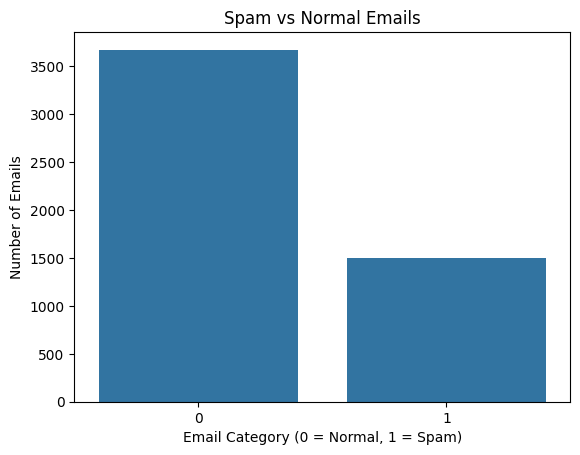

In [75]:
sns.countplot(x='Prediction', data=df)

plt.title('Spam vs Normal Emails')
plt.xlabel('Email Category (0 = Normal, 1 = Spam)')
plt.ylabel('Number of Emails')

plt.show()

In [76]:
X = df.drop(['Email No.', 'Prediction'], axis=1)

y = df['Prediction']

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (5172, 3000)
Target Shape: (5172,)


In [77]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4137, 3000)
Testing Data: (1035, 3000)


In [78]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [79]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

print("KNN Classification Completed!")

KNN Classification Completed!


In [80]:
svm = SVC(kernel='linear')

svm.fit(X_train, y_train)

y_pred_svm = svm.predict(X_test)

print("SVM Classification Completed!")

SVM Classification Completed!


In [81]:
# Calculate confusion matrix for KNN
cm_knn = confusion_matrix(y_test, y_pred_knn)

print("KNN Confusion Matrix:")
print(cm_knn)

# Calculate evaluation metrics
accuracy_knn = accuracy_score(y_test, y_pred_knn)

precision_knn = precision_score(y_test, y_pred_knn)

recall_knn = recall_score(y_test, y_pred_knn)

f1_knn = f1_score(y_test, y_pred_knn)

print("\nKNN Performance:")
print("Accuracy:", accuracy_knn)
print("Precision:", precision_knn)
print("Recall:", recall_knn)
print("F1-Score:", f1_knn)

KNN Confusion Matrix:
[[576 159]
 [ 13 287]]

KNN Performance:
Accuracy: 0.8338164251207729
Precision: 0.6434977578475336
Recall: 0.9566666666666667
F1-Score: 0.7694369973190348


In [82]:
# Calculate confusion matrix for SVM
cm_svm = confusion_matrix(y_test, y_pred_svm)

print("SVM Confusion Matrix:")
print(cm_svm)

# Calculate evaluation metrics
accuracy_svm = accuracy_score(y_test, y_pred_svm)

precision_svm = precision_score(y_test, y_pred_svm)

recall_svm = recall_score(y_test, y_pred_svm)

f1_svm = f1_score(y_test, y_pred_svm)

print("\nSVM Performance:")
print("Accuracy:", accuracy_svm)
print("Precision:", precision_svm)
print("Recall:", recall_svm)
print("F1-Score:", f1_svm)

SVM Confusion Matrix:
[[709  26]
 [ 25 275]]

SVM Performance:
Accuracy: 0.9507246376811594
Precision: 0.9136212624584718
Recall: 0.9166666666666666
F1-Score: 0.9151414309484193


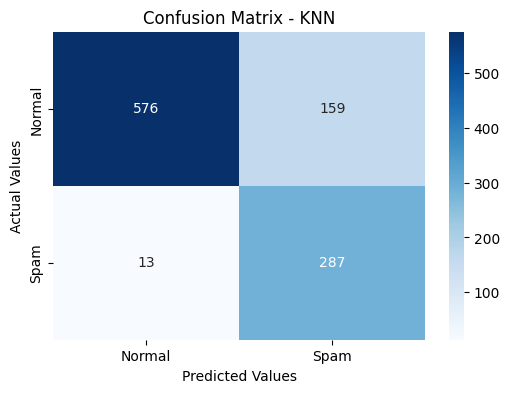

In [83]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Spam"],
    yticklabels=["Normal", "Spam"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Confusion Matrix - KNN")

plt.show()

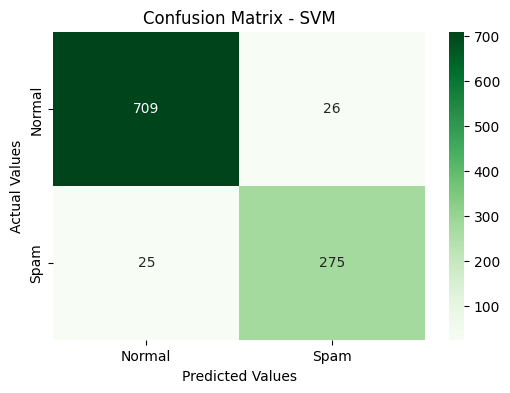

In [84]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Normal", "Spam"],
    yticklabels=["Normal", "Spam"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Confusion Matrix - SVM")

plt.show()